# 2. Recipes and control

The operator-set inputs of the plant (sugar, oil and PAA feeds, aeration, back pressure, water and broth
discharge) follow a **recipe**: piecewise-constant setpoint profiles. This notebook shows how to read and change the
recipe, and how to control the batch yourself, one 12-minute sample at a time.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

from penicillium import BatchSpec, RamanMode, Recipe, SimulationConfig, Simulator, simulate_batches

## The default recipe

`Recipe.default()` is IndPenSim's sequential batch control. Each profile is a list of `(time_h, value)` setpoints,
and a value holds **until** its time: each time is the end of its interval, and the value applies from the
previous time up to and including its own.

In [2]:
recipe = Recipe.default()
print(recipe.at(50.0))  # every input at t = 50 h
print(recipe.profiles["Fs"].setpoints[:6], "...")

{'Fs': 61.0, 'Foil': 35.0, 'Fg': 60.0, 'pressure': 1.1, 'discharge': 0.0, 'Fw': 0.0, 'Fpaa': 10.0}
((3.0, 8.0), (12.0, 15.0), (16.0, 30.0), (20.0, 75.0), (24.0, 150.0), (28.0, 30.0)) ...


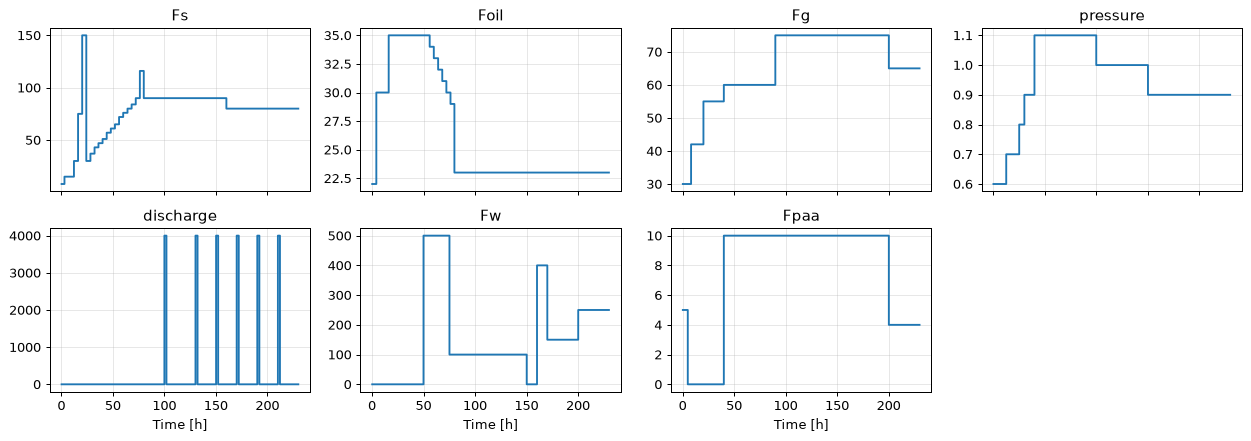

In [3]:
t = np.arange(0.2, 230.01, 0.2)
fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharex=True)
for ax, name in zip(axes.flat, recipe.profiles):
    ax.step(t, [recipe.at(x)[name] for x in t], where="post")
    ax.set_title(name)
axes.flat[-1].axis("off")
for ax in axes[1]:
    ax.set_xlabel("Time [h]")
fig.tight_layout()

## Change the recipe

`Recipe.replace` swaps whole profiles and keeps the others. To compare two recipes fairly, run both on the **same
seeds** (the same batches) and look at the paired differences. `simulate_batches` runs the batches in parallel
processes.

Here the PAA feed is lowered between 40 and 200 h. In the model, PAA above about 2400 mg/L inhibits growth (dotted
line in the plot below), and in many default batches PAA climbs past it. As in every profile, each time is the
end of its interval:

| Interval | 0–5 h | 5–40 h | 40–200 h | 200–300 h | 300–350 h |
|---|---|---|---|---|---|
| Default PAA feed [L/h], `(5, 5), (40, 0), (200, 10), (300, 4), (350, 0)` | 5 | 0 | 10 | 4 | 0 |
| Reduced PAA feed [L/h], `(5, 5), (40, 0), (200, 8), (300, 4), (350, 0)` | 5 | 0 | 8 | 4 | 0 |

The interval of the mean paired difference uses the Student's t quantile for 12 pairs (11 degrees of
freedom).

In [4]:
base = Recipe.default()
less_paa = base.replace(Fpaa=[(5, 5), (40, 0), (200, 8), (300, 4), (350, 0)])  # 8 instead of 10 L/h in 40-200 h

config = SimulationConfig(raman_mode=RamanMode.OFF)  # no spectra: faster
seeds = range(1, 13)
specs = [BatchSpec(seed=s, config=config, recipe=r) for r in (base, less_paa) for s in seeds]
results = simulate_batches(specs, keep_raman=False)

y = np.array([r.total_yield for r in results]).reshape(2, -1)
diff = y[1] - y[0]
half_width = stats.t.ppf(0.975, len(diff) - 1) * diff.std(ddof=1) / np.sqrt(len(diff))  # Student's t, 95 %
print(f"default recipe: {y[0].mean():.0f} kg   less PAA: {y[1].mean():.0f} kg")
print(f"paired difference: {diff.mean():+.0f} ± {half_width:.0f} kg (95 % CI, {len(diff)} batches)")

default recipe: 2633 kg   less PAA: 3473 kg
paired difference: +840 ± 409 kg (95 % CI, 12 batches)


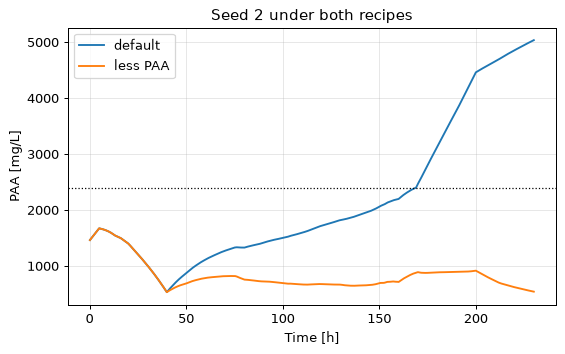

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for res, label in ((results[1], "default"), (results[len(seeds) + 1], "less PAA")):
    ax.plot(res.time, res["PAA"], label=label)
ax.axhline(2400, color="k", ls=":", lw=1)
ax.set(xlabel="Time [h]", ylabel="PAA [mg/L]", title="Seed 2 under both recipes")
ax.legend();

## Step through a batch yourself

`run()` follows the recipe. To decide the inputs yourself, call `reset` and then `step` once per sample.
`recipe_inputs()` returns what the recipe would do next; change any of it before passing it to `step`. The pH and
temperature loops keep running underneath.

Here a simple rule, chosen only to show the mechanics, backs off the sugar feed whenever dissolved oxygen falls
below 10 mg/L.

In [6]:
sim = Simulator()
obs = sim.reset(seed=1)
print("online measurements:", list(obs))

while not sim.done:
    u = sim.recipe_inputs()
    if sim.time > 20 and obs["DO2"] < 10:
        u["Fs"] *= 0.9
    obs, harvested_kg = sim.step(**u)
with_rule = sim.result()
reference = Simulator().run(seed=1)
print(f"recipe: {reference.total_yield:.0f} kg   with the DO2 rule: {with_rule.total_yield:.0f} kg")

online measurements: ['Foil', 'Fw', 'Fs', 'Fa', 'Fb', 'Fc', 'Fh', 'Fg', 'Wt', 'discharge', 'DO2', 'T', 'O2', 'pressure', 'pH']


recipe: 3602 kg   with the DO2 rule: 3591 kg


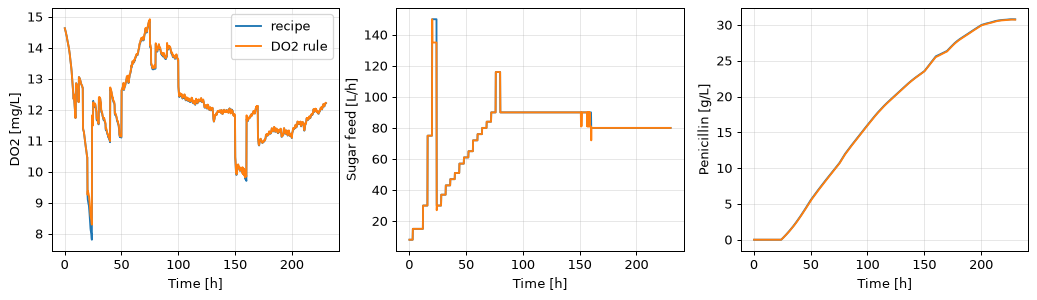

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for res, label in ((reference, "recipe"), (with_rule, "DO2 rule")):
    axes[0].plot(res.time, res["DO2"], label=label)
    axes[1].plot(res.time, res["Fs"], label=label)
    axes[2].plot(res.time, res["P"], label=label)
for ax, lab in zip(axes, ["DO2 [mg/L]", "Sugar feed [L/h]", "Penicillin [g/L]"]):
    ax.set(xlabel="Time [h]", ylabel=lab)
axes[0].legend();

## Control from lab results

Penicillin and PAA are not measured online: the lab reports them every 12 h. This loop adjusts the PAA feed from
each lab result, as the operators of the original plant did by hand. `sim.result()` gives everything recorded so
far, including the lab channels (NaN between reports).

recipe: 2440 kg   PAA from lab: 3710 kg


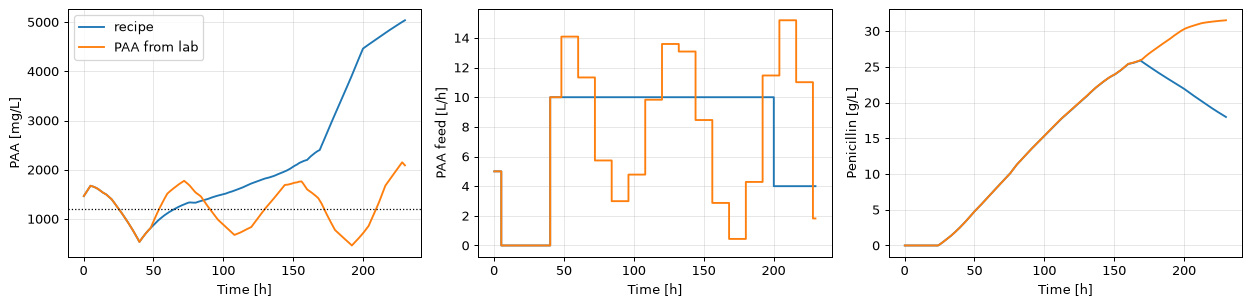

In [8]:
import math


def paa_from_lab(seed, target=1200.0, gain=0.01):
    sim = Simulator()
    sim.reset(seed=seed)
    fpaa = None  # follow the recipe until the first lab result after 40 h
    while not sim.done:
        u = sim.recipe_inputs()
        if fpaa is not None:
            u["Fpaa"] = fpaa
        sim.step(**u)
        if sim.k % 60 == 0 and sim.time >= 40:  # a lab result is reported every 12 h
            paa_lab = sim.result()["PAA_offline"][-1]
            if not math.isnan(paa_lab):
                start = 10.0 if fpaa is None else fpaa
                fpaa = min(max(start + gain * (target - paa_lab), 0.0), 30.0)  # L/h
    return sim.result()


seed = 2
lab_ctrl, recipe_only = paa_from_lab(seed), Simulator().run(seed=seed)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for res, label in ((recipe_only, "recipe"), (lab_ctrl, "PAA from lab")):
    axes[0].plot(res.time, res["PAA"], label=label)
    axes[1].step(res.time, res["Fpaa"], where="post", label=label)
    axes[2].plot(res.time, res["P"], label=label)
axes[0].axhline(1200, color="k", ls=":", lw=1)
for ax, lab in zip(axes, ["PAA [mg/L]", "PAA feed [L/h]", "Penicillin [g/L]"]):
    ax.set(xlabel="Time [h]", ylabel=lab)
axes[0].legend()
fig.tight_layout()
print(f"recipe: {recipe_only.total_yield:.0f} kg   PAA from lab: {lab_ctrl.total_yield:.0f} kg")

[Recipes and control](../control.md) covers the controllers, their tuning and the setpoints. For learning a
controller, see [reinforcement learning](07_reinforcement_learning.ipynb).

**Next:** [Options, faults and disturbances](03_options_faults_disturbances.ipynb).